# RL run: Minesweeper-style, levels 30–80, one stage

Demo run with EnvMinesweeper (global grid + node action). Scheduler: level_hits 30→80, floor linear 1e-4→1e-5. Compare to SharpZ later.


### Summary of Script:

The RL algorithm is working but with two slight issues...

- The actions are concentrated around an area which don't correlate with the problematic nodes
- The action evolution changes the reward a lot, resulting in action which aren't ideal...



In [1]:
import numpy as np
import torch

from som_rl.som.som_backend import SharpZSOMBackend, SharpZBackendConfig
from som_rl.env.schedules import SchedulerConfig, make_scheduler
from som_rl.env.env import SOMEnergyEnvConfig
from som_rl.env.env_multi import EnvMinesweeper

from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import EvalCallback
import gymnasium as gym

DATA = "data"
LEVEL_MIN, LEVEL_MAX = 30, 80
MAX_STEPS = 5000   # per episode (scheduler can terminate earlier when level 80 hits done)
MIN_ACCEPTS_PER_LEVEL = 1

In [2]:
# Load SOM data and build backend
npz = np.load(f"{DATA}/correlations_dl/npairs_compact.npz")
dd, dr, rd, rr = npz["dd"], npz["dr"], npz["rd"], npz["rr"]

node_indices_photo = np.load(f"{DATA}/node_indices_fc.npy")
initial_node_bins  = np.load(f"{DATA}/nodes_labels_initial_fc_200_ext.npy")
reference_labels   = np.load(f"{DATA}/reference_labels_fc_fc.npy")
weighted_clusters  = np.load(f"{DATA}/weighted_clusters_5c_1t200.npy")
umatrix = np.load(f"{DATA}/umat.npy")

b_cfg = SharpZBackendConfig(
    grid_shape=(200, 200),
    num_bins=11,
    objective_mode="energy",
    proposal_bin_mode="uniform_other",
)

def make_backend():
    return SharpZSOMBackend(
        cfg=b_cfg,
        dd=dd, dr=dr, rd=rd, rr=rr,
        node_indices_photo=node_indices_photo,
        initial_node_bins=initial_node_bins,
        reference_labels=reference_labels,
        umatrix=umatrix,
        weighted_clusters=weighted_clusters,
    )

backend = make_backend()
H, W = backend.H, backend.W
print(f"Backend: {H}x{W}, levels 0..{backend.levels_available()-1}")

Backend: 200x200, levels 0..200


In [3]:
# Scheduler: level_hits 30→80, floor linear 1e-4 (level 30) → 1e-5 (level 80)
sched_cfg = SchedulerConfig(
    max_steps=MAX_STEPS,
    level_min=LEVEL_MIN,
    level_max=LEVEL_MAX,
    level_list=tuple(range(LEVEL_MIN, LEVEL_MAX + 1)),
    min_accepts_per_level=MIN_ACCEPTS_PER_LEVEL,
    T_max=1.0,
    T_min=0.01,
    temp_evolve_with="level",
    # Floor: linear in level, decreasing from 1e-4 at level 30 to 1e-5 at level 80
    floor_evolve_with="level",
    min_abs_deltaE=1e-5,
    max_abs_deltaE=1e-4,
    floor_direction="decreasing",
    floor_mode="linear",
    advance_time_on="step",
)
scheduler = make_scheduler("level_hits", sched_cfg)
print("Scheduler: level_hits, floor linear 1e-4→1e-5 with level")

Scheduler: level_hits, floor linear 1e-4→1e-5 with level


In [4]:
# Env config: minesweeper (global obs, node action), scheduler provides level/T/floor
# accept_rule="positive_only": only accept dE > 0 (no SA random acceptance of bad moves)
# use_greedy_bin_for_node=True: same node → same (best) bin proposal → no random-bin lottery
env_cfg = SOMEnergyEnvConfig(
    grid_shape=(200, 200),
    max_steps=MAX_STEPS,
    reset_backend_on_reset=True,
    use_env_max_steps=True,
    reward_type="deltaE",
    use_tanh_reward=True,
    reward_tanh_temperature=1e-4,
    reward_energy_scale=1.0,
    accept_rule="positive_only",
    use_greedy_bin_for_node=True,
    include_umatrix=True,
    include_cluster_features=True,
    include_empty_mask=True,
    include_visit_count=True,
    reject_penalty=0.0,
    noop_penalty=0.0,
)

In [5]:
# Wrapper: add obs["grid"] (C, H, W) for MinesweeperCNNPolicy from base obs
from gymnasium import ObservationWrapper, Wrapper
from gymnasium.spaces import Box, Dict


class DeltaERewardWrapper(Wrapper):
    """Only give positive reward when a new node move is accepted and dE > 0 (real improvement).
    No positive reward for noops or for SA-random acceptance of negative dE."""
    def step(self, action):
        obs, reward, terminated, truncated, info = self.env.step(action)
        accepted = info.get("accepted", False)
        is_noop = info.get("is_noop", True)
        dE = info.get("dE", 0.0)
        # Positive reward only: accepted, not noop, and genuine improvement (dE > 0)
        if accepted and not is_noop and dE > 0:
            new_reward = float(dE)  # or use reward as-is if env already scaled
        else:
            new_reward = 0.0
        return obs, new_reward, terminated, truncated, info


class MinesweeperGridWrapper(ObservationWrapper):
    """Stack grid channels into obs['grid'] (C, H, W) float32."""
    def __init__(self, env, K=11):
        super().__init__(env)
        self.K = K
        # Build new observation_space with "grid" added
        spaces = dict(self.env.observation_space.spaces)
        H, W = spaces["bins"].shape[0], spaces["bins"].shape[1]
        # 6 channels: bins_norm, empty, umatrix, cluster_boundary, cluster_size, visit_count
        spaces["grid"] = Box(low=0.0, high=1.0, shape=(6, H, W), dtype=np.float32)
        self.observation_space = Dict(spaces)

    def observation(self, obs):
        bins = np.asarray(obs["bins"])
        H, W = bins.shape[0], bins.shape[1]
        # normalize bins: -1 -> 0, 0..K-1 -> (1..K)/(K+1)
        bins_float = (bins.astype(np.float32) + 1.0) / (self.K + 1.0)
        empty = np.asarray(obs["empty"], dtype=np.float32)
        umatrix = np.asarray(obs["umatrix"], dtype=np.float32)
        cluster_boundary = np.asarray(obs["cluster_boundary"], dtype=np.float32)
        cluster_size = np.asarray(obs["cluster_size"], dtype=np.float32)
        visit_count = np.asarray(obs["visit_count"], dtype=np.float32)
        obs["grid"] = np.stack([bins_float, empty, umatrix, cluster_boundary, cluster_size, visit_count], axis=0)
        return obs

def make_minesweeper_env(seed=0):
    be = make_backend()
    env = EnvMinesweeper(backend=be, cfg=env_cfg, scheduler=scheduler)
    env = DeltaERewardWrapper(env)
    env = MinesweeperGridWrapper(env, K=be.K)
    env = Monitor(env)
    return env

env = DummyVecEnv([lambda: make_minesweeper_env(0)])

In [6]:
# Custom SB3 feature extractor for Minesweeper (grid + scalars + cursor)
from stable_baselines3.common.torch_layers import BaseFeaturesExtractor
from torch import nn
import torch.nn.functional as F

class MinesweeperExtractor(BaseFeaturesExtractor):
    """Custom CNN+MLP feature extractor for EnvMinesweeper.

    Uses a conv stack on obs["grid"] and an MLP on [scalars, cursor],
    then global average-pools the conv features (MPS-safe) and concatenates.
    """

    def __init__(self, observation_space, grid_channels=6, hidden_dim=256):
        # output feature dim for actor/critic
        self._hidden_dim = hidden_dim
        super().__init__(observation_space, features_dim=hidden_dim)

        self.conv = nn.Sequential(
            nn.Conv2d(grid_channels, 32, kernel_size=8, stride=4),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=4, stride=2),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, stride=1),
            nn.ReLU(),
        )
        self.scalar_mlp = nn.Sequential(
            nn.Linear(6, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
        )
        # conv global avg -> (B,64), scalar_mlp -> (B,64) ⇒ concat to 128
        self.fc = nn.Linear(64 + 64, hidden_dim)

    def forward(self, observations):
        grid = observations["grid"]              # (B, C, H, W)
        z = self.conv(grid)                       # (B, 64, H', W')
        z = z.mean(dim=(-2, -1))                  # global avg pool → (B, 64)

        s = torch.cat(
            [observations["scalars"], observations["cursor"].float()],
            dim=-1,
        )                                        # (B, 6)
        s = self.scalar_mlp(s)                   # (B, 64)

        h = torch.cat([z, s], dim=-1)            # (B, 128)
        return F.relu(self.fc(h))                # (B, hidden_dim)

In [7]:
# PPO with custom Minesweeper feature extractor (one stage)
device = "mps" if torch.backends.mps.is_available() else "cpu"
n_actions = H * W

model = PPO(
    "MultiInputPolicy",
    env,
    policy_kwargs=dict(
        features_extractor_class=MinesweeperExtractor,
        features_extractor_kwargs=dict(grid_channels=6, hidden_dim=256),
        net_arch=dict(pi=[64, 64], vf=[64, 64]),
    ),
    learning_rate=3e-4,
    n_steps=2048,
    batch_size=64,
    n_epochs=10,
    gamma=0.99,
    gae_lambda=0.95,
    clip_range=0.2,
    ent_coef=0.01,
    verbose=1,
    device=device,
)

print("PPO model created; ready to train.")

Using mps device
PPO model created; ready to train.


In [8]:
# Train one stage (adjust total_timesteps as needed)
total_timesteps = 200_000  # demo
# Use progress_bar=False unless you have: pip install stable-baselines3[extra]
model.learn(total_timesteps=total_timesteps, progress_bar=True)

Output()

-----------------------------
| time/              |      |
|    fps             | 71   |
|    iterations      | 1    |
|    time_elapsed    | 28   |
|    total_timesteps | 2048 |
-----------------------------


-----------------------------------------
| time/                   |             |
|    fps                  | 62          |
|    iterations           | 2           |
|    time_elapsed         | 66          |
|    total_timesteps      | 4096        |
| train/                  |             |
|    approx_kl            | 0.046093345 |
|    clip_fraction        | 0.753       |
|    clip_range           | 0.2         |
|    entropy_loss         | -10.6       |
|    explained_variance   | -35.7       |
|    learning_rate        | 0.0003      |
|    loss                 | -0.271      |
|    n_updates            | 10          |
|    policy_gradient_loss | -0.137      |
|    value_loss           | 0.00348     |
-----------------------------------------


-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 5e+03       |
|    ep_rew_mean          | 0.00642     |
| time/                   |             |
|    fps                  | 58          |
|    iterations           | 3           |
|    time_elapsed         | 105         |
|    total_timesteps      | 6144        |
| train/                  |             |
|    approx_kl            | 0.042258233 |
|    clip_fraction        | 0.826       |
|    clip_range           | 0.2         |
|    entropy_loss         | -10.6       |
|    explained_variance   | -6.92       |
|    learning_rate        | 0.0003      |
|    loss                 | -0.254      |
|    n_updates            | 20          |
|    policy_gradient_loss | -0.135      |
|    value_loss           | 0.000179    |
-----------------------------------------


----------------------------------------
| rollout/                |            |
|    ep_len_mean          | 5e+03      |
|    ep_rew_mean          | 0.00642    |
| time/                   |            |
|    fps                  | 57         |
|    iterations           | 4          |
|    time_elapsed         | 142        |
|    total_timesteps      | 8192       |
| train/                  |            |
|    approx_kl            | 0.03119944 |
|    clip_fraction        | 0.693      |
|    clip_range           | 0.2        |
|    entropy_loss         | -10.6      |
|    explained_variance   | -0.06      |
|    learning_rate        | 0.0003     |
|    loss                 | -0.172     |
|    n_updates            | 30         |
|    policy_gradient_loss | -0.0669    |
|    value_loss           | 0.000567   |
----------------------------------------


-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 5e+03       |
|    ep_rew_mean          | 0.00653     |
| time/                   |             |
|    fps                  | 56          |
|    iterations           | 5           |
|    time_elapsed         | 179         |
|    total_timesteps      | 10240       |
| train/                  |             |
|    approx_kl            | 0.048862398 |
|    clip_fraction        | 0.817       |
|    clip_range           | 0.2         |
|    entropy_loss         | -10.6       |
|    explained_variance   | -1.63       |
|    learning_rate        | 0.0003      |
|    loss                 | -0.214      |
|    n_updates            | 40          |
|    policy_gradient_loss | -0.116      |
|    value_loss           | 6.59e-05    |
-----------------------------------------


... (89 outputs left out)

----------------------------------------
| rollout/                |            |
|    ep_len_mean          | 4.47e+03   |
|    ep_rew_mean          | 0.00656    |
| time/                   |            |
|    fps                  | 54         |
|    iterations           | 95         |
|    time_elapsed         | 3559       |
|    total_timesteps      | 194560     |
| train/                  |            |
|    approx_kl            | 0.06422323 |
|    clip_fraction        | 0.818      |
|    clip_range           | 0.2        |
|    entropy_loss         | -10.6      |
|    explained_variance   | -34.9      |
|    learning_rate        | 0.0003     |
|    loss                 | -0.208     |
|    n_updates            | 940        |
|    policy_gradient_loss | -0.112     |
|    value_loss           | 2.21e-06   |
----------------------------------------


----------------------------------------
| rollout/                |            |
|    ep_len_mean          | 4.47e+03   |
|    ep_rew_mean          | 0.00656    |
| time/                   |            |
|    fps                  | 54         |
|    iterations           | 96         |
|    time_elapsed         | 3592       |
|    total_timesteps      | 196608     |
| train/                  |            |
|    approx_kl            | 0.07045538 |
|    clip_fraction        | 0.831      |
|    clip_range           | 0.2        |
|    entropy_loss         | -10.6      |
|    explained_variance   | -39        |
|    learning_rate        | 0.0003     |
|    loss                 | -0.27      |
|    n_updates            | 950        |
|    policy_gradient_loss | -0.135     |
|    value_loss           | 1.31e-06   |
----------------------------------------


----------------------------------------
| rollout/                |            |
|    ep_len_mean          | 4.48e+03   |
|    ep_rew_mean          | 0.00656    |
| time/                   |            |
|    fps                  | 54         |
|    iterations           | 97         |
|    time_elapsed         | 3632       |
|    total_timesteps      | 198656     |
| train/                  |            |
|    approx_kl            | 0.08319306 |
|    clip_fraction        | 0.873      |
|    clip_range           | 0.2        |
|    entropy_loss         | -10.6      |
|    explained_variance   | -21.1      |
|    learning_rate        | 0.0003     |
|    loss                 | -0.266     |
|    n_updates            | 960        |
|    policy_gradient_loss | -0.138     |
|    value_loss           | 9.09e-07   |
----------------------------------------


----------------------------------------
| rollout/                |            |
|    ep_len_mean          | 4.48e+03   |
|    ep_rew_mean          | 0.00656    |
| time/                   |            |
|    fps                  | 54         |
|    iterations           | 98         |
|    time_elapsed         | 3668       |
|    total_timesteps      | 200704     |
| train/                  |            |
|    approx_kl            | 0.08744553 |
|    clip_fraction        | 0.886      |
|    clip_range           | 0.2        |
|    entropy_loss         | -10.6      |
|    explained_variance   | -14.9      |
|    learning_rate        | 0.0003     |
|    loss                 | -0.283     |
|    n_updates            | 970        |
|    policy_gradient_loss | -0.151     |
|    value_loss           | 9.1e-07    |
----------------------------------------


In [9]:
# Save model for later comparison with SharpZ
import os
os.makedirs("models", exist_ok=True)
model.save("models/ppo_minesweeper_l30_80_demo")
print("Saved to models/ppo_minesweeper_l30_80_demo.zip")

Saved to models/ppo_minesweeper_l30_80_demo.zip


In [13]:
# Quick eval: run a few episodes and report mean reward
rewards_list = []
for ep in range(3):
    obs = env.reset()
    done = [False]
    total_r = 0.0
    while not done[0]:
        action, _ = model.predict(obs, deterministic=False)
        obs, r, done, info = env.step(action)
        total_r += float(r[0])
    rewards_list.append(total_r)
print(f"Eval (3 eps): mean reward = {np.mean(rewards_list):.4f}")

Eval (3 eps): mean reward = 0.0068


In [11]:
# Logged eval: single PPO run with full action history + filterable successes
import pandas as pd

def run_logged_episode_eval(model, max_steps=MAX_STEPS, seed=3):
    """Run one episode in a fresh EnvMinesweeper and return (env, log_df).

    log_df columns include t, level, T, floor, action/node/x/y, reward, dE,
    accepted, is_noop so you can filter "successful" actions.
    """
    # Fresh backend + scheduler so training state is untouched
    be = make_backend()
    eval_sched = make_scheduler("level_hits", sched_cfg)
    base_env = EnvMinesweeper(backend=be, cfg=env_cfg, scheduler=eval_sched)
    eval_env = DeltaERewardWrapper(base_env)
    eval_env = MinesweeperGridWrapper(eval_env, K=be.K)

    obs, info = eval_env.reset(seed=seed)
    logs = []

    # Unwrap to get EnvMinesweeper (Grid -> DeltaEReward -> Minesweeper)
    base_env = eval_env.env.env

    for t in range(1, max_steps + 1):
        # Snapshot bins before the action
        bins_before = base_env.som.current_bins.copy()

        action, _ = model.predict(obs, deterministic=False)
        obs, reward, terminated, truncated, info = eval_env.step(action)

        # In EnvMinesweeper, action is node_idx
        node = int(action)
        x = y = None
        old_bin = new_bin = None
        if 0 <= node < base_env.som.N:
            x, y = base_env.som.index_to_xy(node)
            old_bin = int(bins_before[node])
            new_bin = int(base_env.som.current_bins[node])

        dE = float(info.get("dE", 0.0))

        logs.append({
            "t": t,
            "level": info.get("level", None),
            "T": info.get("T", None),
            "floor": info.get("min_delta_E", None),
            "action": node,
            "node": node,
            "x": x,
            "y": y,
            "old_bin": old_bin,
            "new_bin": new_bin,
            "reward": float(reward),
            "dE": dE,
            "accepted": bool(info.get("accepted", False)),
            "is_noop": bool(info.get("is_noop", False)),
        })

        if terminated or truncated:
            break

    log_df = pd.DataFrame(logs)
    return eval_env, log_df

# Example usage: run one eval episode and inspect actions
eval_env, log_df = run_logged_episode_eval(model, max_steps=MAX_STEPS, seed=123)
print("Episode steps:", len(log_df))
print("First few actions:")
display(log_df.head())

# Filter for "successful" actions: accepted with positive ΔE
success_df = log_df[(log_df["accepted"]) & (log_df["dE"] > 0)]
print("Successful actions (accepted & dE>0):", len(success_df))
display(success_df.head())

Episode steps: 4771
First few actions:


,t,level,T,floor,action,node,x,y,old_bin,new_bin,reward,dE,accepted,is_noop
0,1,30,1.0,0.0001,19234,19234,34,96,6,6,0.0,-0.000253,False,False
1,2,30,1.0,0.0001,19928,19928,128,99,4,4,0.0,-0.000010,False,False
2,3,30,1.0,0.0001,21973,21973,173,109,2,2,0.0,0.000004,False,False
3,4,30,1.0,0.0001,29126,29126,126,145,1,1,0.0,-0.000017,False,False
4,5,30,1.0,0.0001,25887,25887,87,129,8,8,0.0,0.000047,False,False


Successful actions (accepted & dE>0): 51


,t,level,T,floor,action,node,x,y,old_bin,new_bin,reward,dE,accepted,is_noop
7,8,30,1.000000,0.000100,32670,32670,70,163,6,10,0.000227,0.000227,True,False
17,18,31,0.912011,0.000098,27878,27878,78,139,10,9,0.000694,0.000694,True,False
19,20,32,0.831764,0.000096,32452,32452,52,162,4,8,0.000248,0.000248,True,False
31,32,33,0.758578,0.000095,30801,30801,1,154,9,8,0.000256,0.000256,True,False
39,40,34,0.691831,0.000093,24879,24879,79,124,6,8,0.000300,0.000300,True,False


In [12]:
log_df

,t,level,T,floor,action,node,x,y,old_bin,new_bin,reward,dE,accepted,is_noop
0,1,30,1.00,0.00010,19234,19234,34,96,6,6,0.000000,-2.527563e-04,False,False
1,2,30,1.00,0.00010,19928,19928,128,99,4,4,0.000000,-1.020320e-05,False,False
2,3,30,1.00,0.00010,21973,21973,173,109,2,2,0.000000,3.743577e-06,False,False
3,4,30,1.00,0.00010,29126,29126,126,145,1,1,0.000000,-1.679782e-05,False,False
4,5,30,1.00,0.00010,25887,25887,87,129,8,8,0.000000,4.667757e-05,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4766,4767,80,0.01,0.00001,33917,33917,117,169,3,3,0.000000,-9.000294e-07,False,False
4767,4768,80,0.01,0.00001,22529,22529,129,112,1,1,0.000000,-6.822337e-06,False,False
4768,4769,80,0.01,0.00001,12475,12475,75,62,5,5,0.000000,-1.725948e-05,False,False
4769,4770,80,0.01,0.00001,35767,35767,167,178,3,3,0.000000,-9.503163e-08,False,False


In [46]:
# Interactive: step through successful actions and see SOM state after each
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider

base_env = eval_env.env.env
som = base_env.som
H, W = som.H, som.W
success_df = log_df[(log_df["accepted"]) & (log_df["dE"] > 0)].copy().reset_index(drop=True)

# Replay episode to get SOM state after each successful action (cluster moves applied correctly)
bins = np.array(som.initial_bins, copy=True)
successful_states = [bins.copy()]  # state before first success
for _, row in log_df.iterrows():
    if row["accepted"] and row["dE"] > 0:
        node, level, new_bin = int(row["node"]), row["level"], int(row["new_bin"])
        if level is not None and 0 <= node < len(bins):
            try:
                cid = som.cluster_id_for_node(node, int(level))
                nodes = som.nodes_for_cluster_id(int(level), cid)
                bins[nodes] = new_bin
            except Exception:
                bins[node] = new_bin
        else:
            if 0 <= node < len(bins):
                bins[node] = new_bin
        successful_states.append(bins.copy())

# successful_states[k] = SOM after k-th successful action (k=0 is after 0 successes = initial)
n_success = len(successful_states) - 1
if n_success == 0:
    print("No successful actions in this episode.")
else:
    def show_step(k):
        k = int(np.clip(k, 0, n_success))
        fig, ax = plt.subplots(figsize=(6, 6))
        grid = successful_states[k].reshape(H, W)
        ax.imshow(grid, vmin=0, vmax=9)
        if k == 0:
            ax.set_title("Initial SOM (before any successful action)")
        else:
            row = success_df.iloc[k - 1]
            ax.set_title(f"After success {k}/{n_success}: t={row['t']} node={row['node']} (x,y)=({row['x']},{row['y']}) dE={row['dE']:.2e}")
        ax.set_axis_off()
        plt.tight_layout()
        plt.show()

    interact(show_step, k=IntSlider(min=0, max=n_success, step=1, value=0, description="Success #"))

interactive(children=(IntSlider(value=0, description='Success #', max=51), Output()), _dom_classes=('widget-in…

## SOM comparison and action-map analysis

Below: (1) view SOM after one episode vs perfect (reference) and starting; (2) build an action heatmap from ~200k actions (cluster hits); (3) plot action map vs diff (perfect vs start) to show correlation.

In [ ]:
from som_rl.som.som_backend import SharpZSOMBackend, SharpZBackendConfig
from som_rl.eval.ideal_som import get_perfect_bins, plot_bins_triptych

In [16]:
perfect_bins = get_perfect_bins()

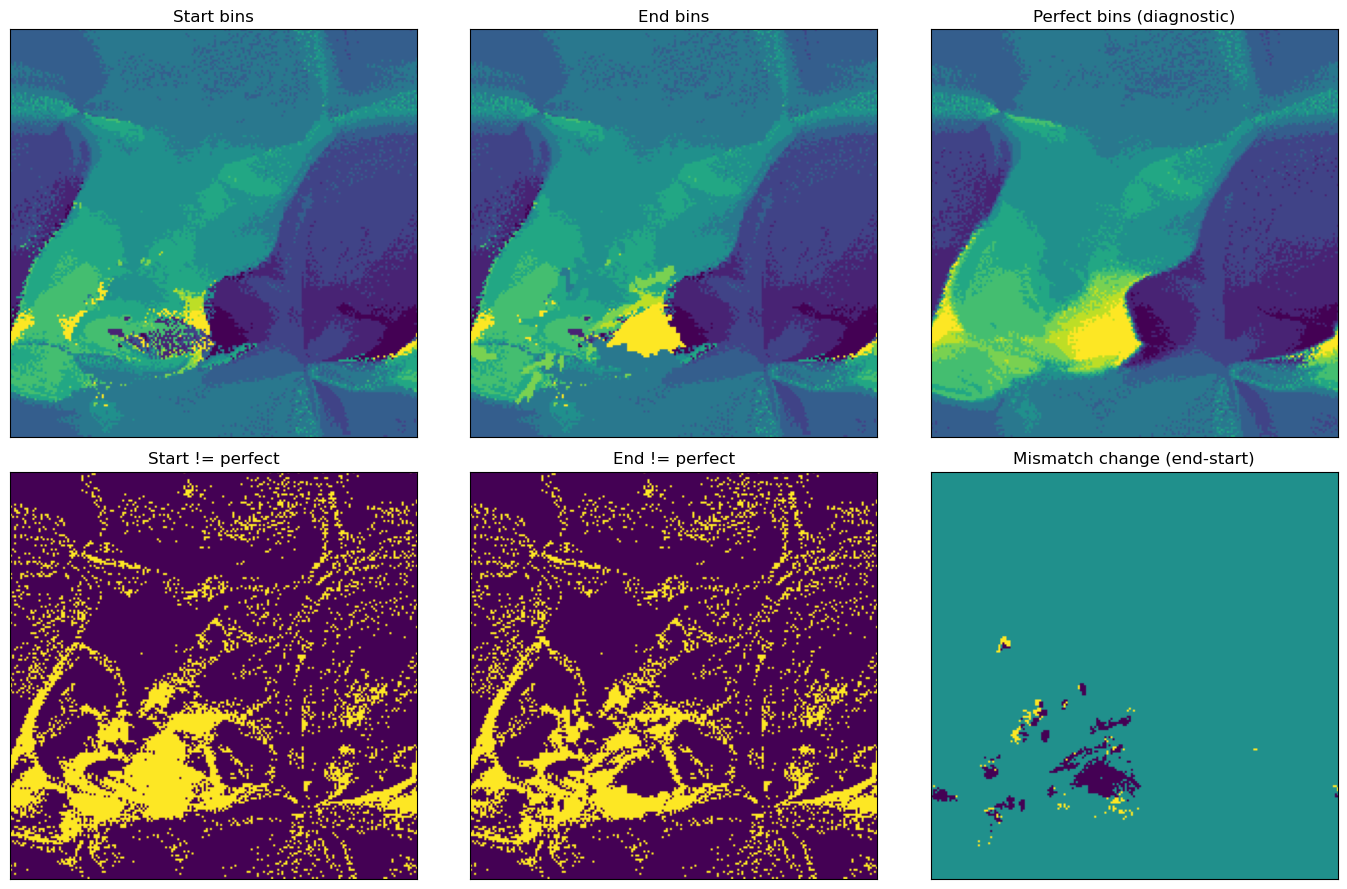

Match to perfect: start=0.795, end=0.810, Δ=+0.015


In [24]:
# 1) SOM after one episode vs perfect (reference) and starting
# Run the "run_logged_episode_eval" cell above first so eval_env and log_df exist.
import matplotlib.pyplot as plt

base_env = eval_env.env.env
som = base_env.som
H, W = som.H, som.W

perfect = perfect_bins.reshape(H, W)
start = som.initial_bins.reshape(H, W)
after = som.current_bins.reshape(H, W)

plot_bins_triptych(start,after, perfect_bins)

In [ ]:
# 2) Collect ~200k actions across multiple runs and build action heatmap
# Each time a cluster is "hit" (action on a node at a level), all nodes in that cluster get +1.
TARGET_ACTIONS = 200_000
action_logs = []
total_actions = 0
seed = 0
while total_actions < TARGET_ACTIONS:
    eval_env, log_df = run_logged_episode_eval(model, max_steps=MAX_STEPS, seed=seed)
    action_logs.append(log_df[["node", "level"]].copy())
    total_actions += len(log_df)
    seed += 1
    if seed % 10 == 0:
        print(f"Seed {seed}, total actions so far: {total_actions}")

all_actions = pd.concat(action_logs, ignore_index=True)
print(f"Collected {len(all_actions)} actions from {len(action_logs)} episodes.")

# Use one backend for cluster lookup (same weighted_clusters everywhere)
be = make_backend()
N = be.N
H, W = be.H, be.W
action_count = np.zeros(N, dtype=np.int64)
for _, row in all_actions.iterrows():
    node = int(row["node"])
    level = row["level"]
    if level is None or node < 0 or node >= N:
        continue
    level = int(level)
    try:
        cid = be.cluster_id_for_node(node, level)
        nodes = be.nodes_for_cluster_id(level, cid)
        action_count[nodes] += 1
    except Exception:
        pass

action_map = action_count.reshape(H, W)

KeyboardInterrupt: 

In [43]:
# Use one backend for cluster lookup (same weighted_clusters everywhere)
be = make_backend()
N = be.N
H, W = be.H, be.W
action_count = np.zeros(N, dtype=np.int64)
for _, row in all_actions.iterrows():
    node = int(row["node"])
    level = row["level"]
    if level is None or node < 0 or node >= N:
        continue
    level = int(level)
    try:
        cid = be.cluster_id_for_node(node, level)
        nodes = be.nodes_for_cluster_id(level, cid)
        action_count[nodes] += 1
    except Exception:
        pass

action_map = action_count.reshape(H, W)

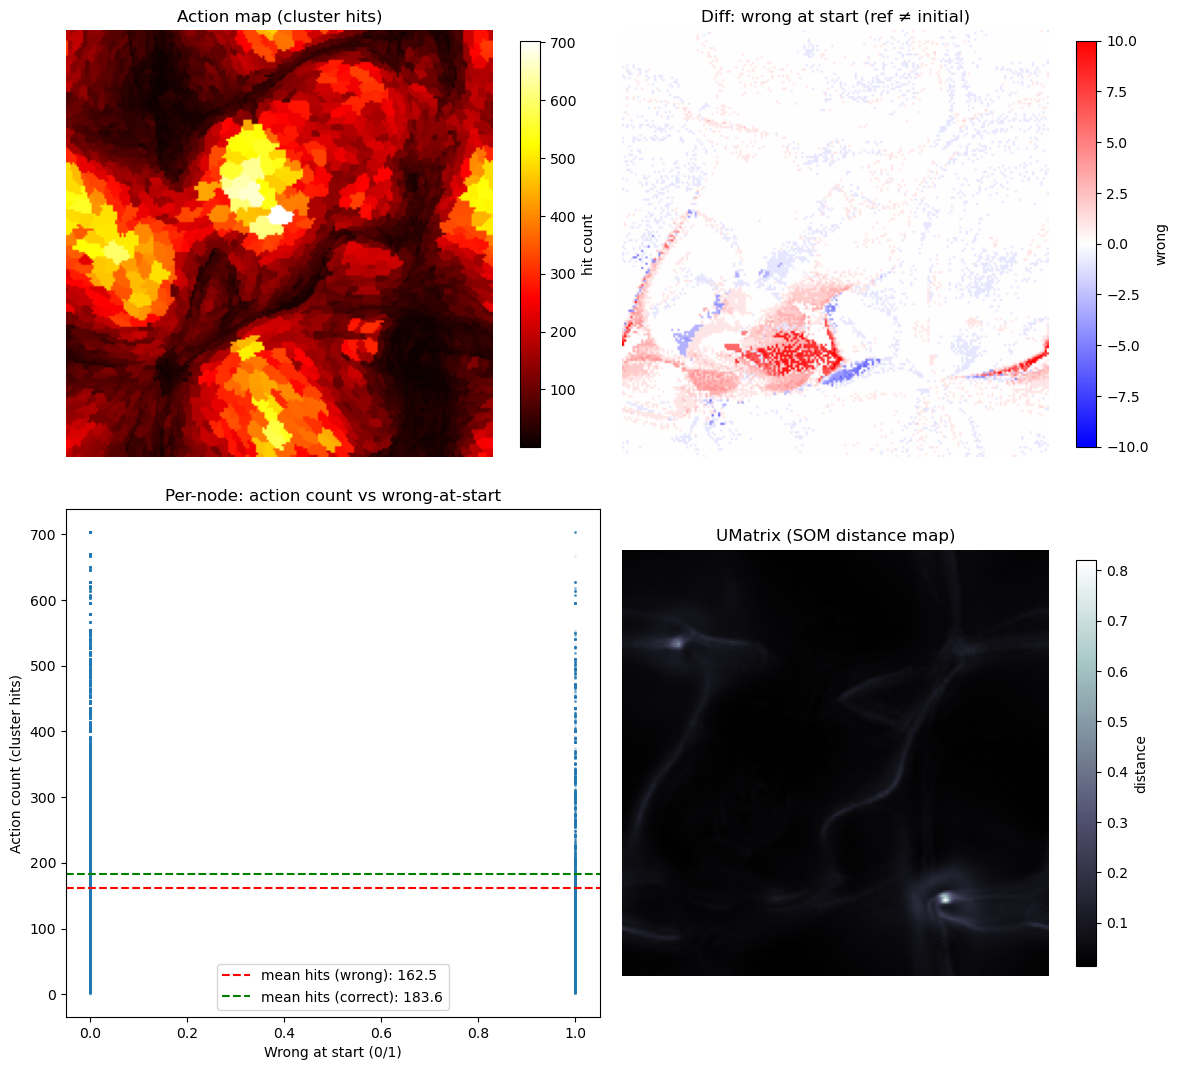

Correlation (wrong-at-start vs action count)
r = -0.0590


In [44]:
# 3) Diff map (perfect vs starting SOM) and correlation with action map
# Diff: 1 where reference != initial_bins (node "wrong" at start), 0 else.
diff_start = (perfect - start).astype(np.float32)
diff_flat = (perfect != start).astype(np.float32).ravel()  # 1D to match action_count (N,)

fig, axes = plt.subplots(2, 2, figsize=(12, 11))

# Action heatmap
ax = axes[0, 0]
# flip the action map
im0 = ax.imshow(action_map, cmap="hot")
ax.set_title("Action map (cluster hits)")
ax.set_axis_off()
plt.colorbar(im0, ax=ax, label="hit count", shrink=0.8)

# Diff heatmap (perfect vs start)
ax = axes[0, 1]
im1 = ax.imshow(diff_start, cmap="bwr", vmin=-10, vmax=10)
ax.set_title("Diff: wrong at start (ref ≠ initial)")
ax.set_axis_off()
plt.colorbar(im1, ax=ax, label="wrong", shrink=0.8)

# Overlay or correlation: scatter node-level action count vs diff
ax = axes[1, 0]
ax.scatter(diff_flat, action_count, alpha=0.1, s=1)
ax.set_xlabel("Wrong at start (0/1)")
ax.set_ylabel("Action count (cluster hits)")
ax.set_title("Per-node: action count vs wrong-at-start")
# Mean action count for wrong vs correct
wrong = np.asarray(diff_flat).astype(bool).ravel()  # 1D so action_count[wrong] works
ax.axhline(action_count[wrong].mean(), color="red", ls="--", label=f"mean hits (wrong): {action_count[wrong].mean():.1f}")
ax.axhline(action_count[~wrong].mean(), color="green", ls="--", label=f"mean hits (correct): {action_count[~wrong].mean():.1f}")
ax.legend()

# umatrix from som
ax = axes[1, 1]
umatrix = som.umatrix_grid()
im2 = ax.imshow(umatrix, cmap="bone")
ax.set_title("UMatrix (SOM distance map)")
ax.set_axis_off()
plt.colorbar(im2, ax=ax, label="distance", shrink=0.8)


plt.tight_layout()
plt.show()

r = np.corrcoef(diff_flat, action_count)[0, 1]
print(f"Correlation (wrong-at-start vs action count)\nr = {r:.4f}")
